In [ ]:
# loading event streams
import numpy as np
from pathlib import Path


normal_files = sorted(
    Path("normal_dset/Normal_Videos_003-_944").glob("*.npz")
)

fighting_files = sorted(
    Path("dataset/Abuse-Fighting/Fighting").glob("*.npz")
)

print(f"Found {len(normal_files)} normal videos")
print(f"Found {len(fighting_files)} fighting videos")




Found 158 normal videos
Found 53 fighting videos


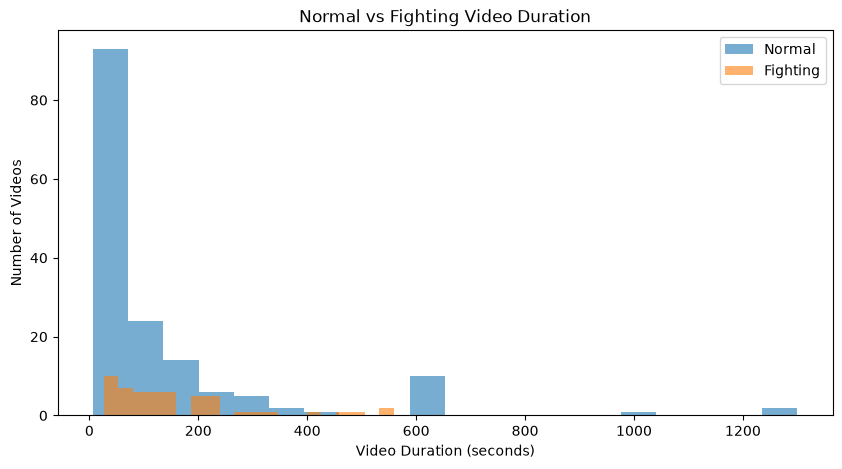

In [34]:
# normal video duration distribution
import numpy as np
import matplotlib.pyplot as plt

normal_durations = []
fighting_durations = []

# Normal
for f in normal_files:
    d = np.load(f)

    duration = (
        d["t"][-1] - d["t"][0]
    ) / 1e6

    normal_durations.append(duration)

# Fighting
for f in fighting_files:
    d = np.load(f)

    duration = (
        d["t"][-1] - d["t"][0]
    ) / 1e6

    fighting_durations.append(duration)

# Plot
plt.figure(figsize=(10,5))

plt.hist(
    normal_durations,
    bins=20,
    alpha=0.6,
    label="Normal"
)

plt.hist(
    fighting_durations,
    bins=20,
    alpha=0.6,
    label="Fighting"
)

plt.xlabel("Video Duration (seconds)")
plt.ylabel("Number of Videos")
plt.title("Normal vs Fighting Video Duration")
plt.legend()

plt.show()

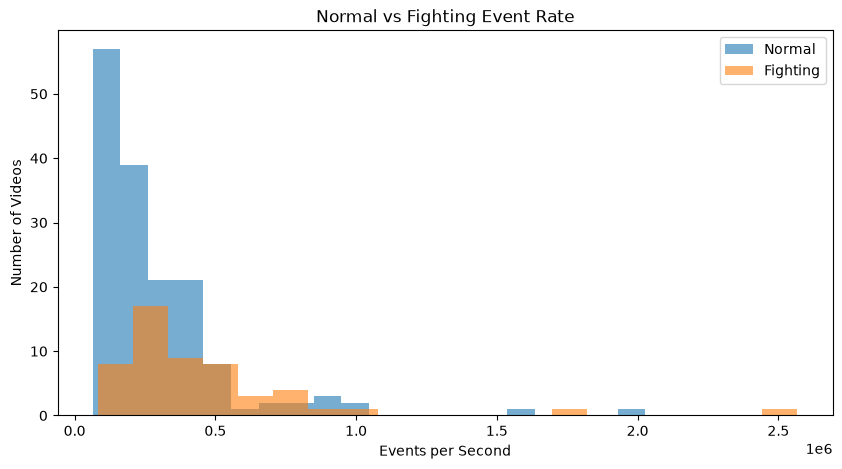

In [35]:
# event rate plots - fighting, normal
normal_rates = []
fighting_rates = []

for f in normal_files:
    d = np.load(f)

    duration = (d["t"][-1] - d["t"][0]) / 1e6

    normal_rates.append(
        len(d["t"]) / duration
    )

for f in fighting_files:
    d = np.load(f)

    duration = (d["t"][-1] - d["t"][0]) / 1e6

    fighting_rates.append(
        len(d["t"]) / duration
    )

plt.figure(figsize=(10,5))

plt.hist(normal_rates, bins=20, alpha=0.6,
         label="Normal")

plt.hist(fighting_rates, bins=20, alpha=0.6,
         label="Fighting")

plt.xlabel("Events per Second")
plt.ylabel("Number of Videos")
plt.title("Normal vs Fighting Event Rate")
plt.legend()

plt.show() 


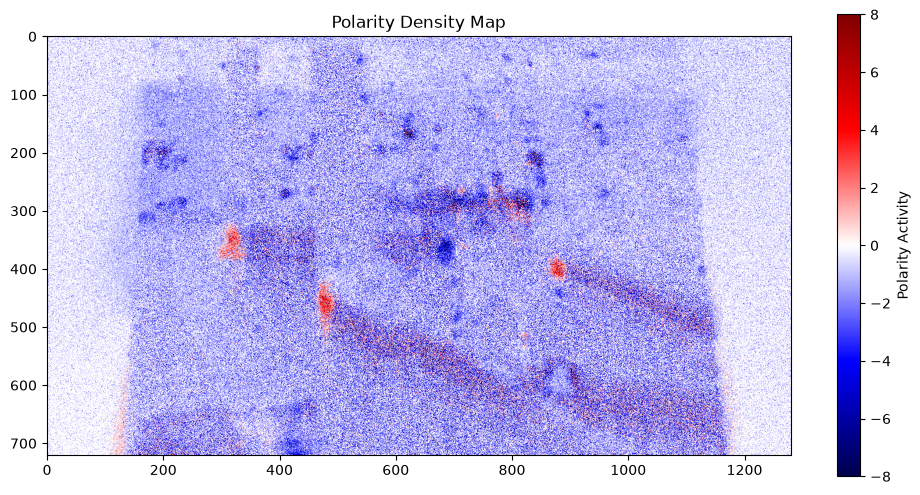

In [ ]:
# polar density map for normal event
sample_normal = np.load(normal_files[5])
p_vis = np.where(sample_normal["p"] == 0, -1, 1)
density = np.zeros((720, 1280), dtype=np.float32)

np.add.at(
    density,
    (sample_normal["y"], sample_normal["x"]),
    p_vis
)

plt.figure(figsize=(12,6))

v = np.percentile(np.abs(density), 99)

plt.imshow(
    density,
    cmap="seismic",
    vmin=-v,
    vmax=v
)

plt.colorbar(label="Polarity Activity")
plt.title("Polarity Density Map")

plt.show()


In [52]:

def create_slices(data, window_ms=50):

    t = data["t"]
    x = data["x"]
    y = data["y"]
    p = data["p"]

    window_us = window_ms * 1000

    slices = []

    current = t[0]

    while current < t[-1]:

        nxt = current + window_us

        mask = (t >= current) & (t < nxt)

        pos_frame = np.zeros((720, 1280), dtype=np.float32)
        neg_frame = np.zeros((720, 1280), dtype=np.float32)

        pos_mask = mask & (p == 1)
        neg_mask = mask & (p == 0)

        np.add.at(
            pos_frame,
            (y[pos_mask], x[pos_mask]),
            1
        )

        np.add.at(
            neg_frame,
            (y[neg_mask], x[neg_mask]),
            1
        )

        # shape = (2, H, W)
        slices.append(
            np.stack([neg_frame, pos_frame])
        )

        current = nxt

    return np.array(slices)


In [53]:
sample_normal_sliced = create_slices(
    sample_normal,
    window_ms=50
)

print(sample_normal_sliced.shape)

(768, 2, 720, 1280)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML

# animates slices to visualise in video-like representation
def animate_slices(
    slices,
    max_frames=100,
    interval=100,
    window_ms=50,
    cmap="bwr"
):
    """
    slices shape:
        (N, 2, H, W)

    channel 0 = negative events
    channel 1 = positive events
    """

    frames = slices[:, 1] - slices[:, 0]

    n_frames = min(len(frames), max_frames)

    v = np.percentile(
        np.abs(frames[:n_frames]),
        99
    )

    fig, ax = plt.subplots(figsize=(8, 5))

    img = ax.imshow(
        frames[0],
        cmap=cmap,
        vmin=-v,
        vmax=v
    )

    ax.axis("off")

    def update(i):

        img.set_data(frames[i])

        ax.set_title(
            f"Slice {i}  |  "
            f"{i*window_ms}-{(i+1)*window_ms} ms"
        )

        return [img]

    anim = animation.FuncAnimation(
        fig,
        update,
        frames=n_frames,
        interval=interval,
        blit=True
    )

    plt.close()

    return HTML(anim.to_jshtml())